# ELECTRA-small · AI or human?

**Owner:** Member 2 · **Checkpoint:** `google/electra-small-discriminator`

**About this model.** ELECTRA learns in a different way from BERT. During pre-training a small generator replaces some words, and ELECTRA (the **discriminator**) must say for every word whether it is original or replaced. This uses every word for learning, so even the small version is strong. It has only about 14 million parameters, the smallest model in our comparison.

**Plan of this notebook** (the same in all six model notebooks, so results are fair):

1. Read the shared train / validation / test files.
2. Turn the text into tokens.
3. Fine-tune the pretrained model for 2 epochs and keep the epoch with the best validation F1.
4. Save the model.
5. Explain one correct and one wrong prediction with LIME.
6. Test once on the test set: metrics, confusion matrix, size and speed.
7. Look at the mistakes.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

SEED = 42
DATA = Path('../data')
MODELS = Path('../models')
DOCS = Path('../docs')

NAME = 'ELECTRA-small'
CHECKPOINT = 'google/electra-small-discriminator'
FOLDER = MODELS / NAME

set_seed(SEED)   # same seed as every other notebook

/Users/mac/Documents/AI-PROJECT/AI-Human-Detection/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Read the shared data

All seven models use the **same** CSV files from notebook 00. That is what makes the comparison fair.

In [2]:
train = pd.read_csv(DATA / 'train.csv')
val = pd.read_csv(DATA / 'val.csv')
test = pd.read_csv(DATA / 'test.csv')
print('train:', len(train), '| val:', len(val), '| test:', len(test))
train.head()

train: 700 | val: 150 | test: 150


,pair_id,text,label
0,79,"Elizabeth Cady Stanton (November 12, 1815 – Oc...",0
1,250,The Tour de France is an annual multiple stage...,0
2,198,The seven SI base units and the interdependenc...,0
3,77,A law enforcement murder book is a comprehensi...,1
4,160,An assist in basketball is a pass that directl...,1


## 2. Tokenize

A transformer does not read words. It reads **tokens**: pieces of words, each with an id number.
Every checkpoint has its own tokenizer, so we load the one that matches our model.

We cut every answer at **128 tokens** to keep training fast. Most human answers are shorter than that; long ChatGPT answers lose their end, but their beginning is enough to show the style.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

example = 'Farmington Hills is a city located in Oakland County, Michigan.'
print('Tokens:', tokenizer.tokenize(example))
print('Ids:   ', tokenizer(example)['input_ids'])

Tokens: ['farming', '##ton', 'hills', 'is', 'a', 'city', 'located', 'in', 'oakland', 'county', ',', 'michigan', '.']
Ids:    [101, 7876, 2669, 4564, 2003, 1037, 2103, 2284, 1999, 9182, 2221, 1010, 4174, 1012, 102]


In [4]:
def tokenize(batch):
    return tokenizer(batch['text'], truncation=True, max_length=128)

train_data = Dataset.from_pandas(train[['text', 'label']]).map(tokenize, batched=True)
val_data = Dataset.from_pandas(val[['text', 'label']]).map(tokenize, batched=True)
print(train_data)

Map:   0%|          | 0/700 [00:00<?, ? examples/s]

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
Map: 100%|██████████| 700/700 [00:00<00:00, 14011.77 examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

Map: 100%|██████████| 150/150 [00:00<00:00, 16818.03 examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 700
})


## 3. Fine-tune

**Fine-tuning** = start from a model that already understands English (pretrained) and train it a little more on our task.
We add a small new layer on top (the *classification head*) with 2 outputs: Human and AI.

Training settings (the same for all six models):

| Setting | Value | Why |
|---|---|---|
| epochs | 2 | two passes over the 700 answers; enough for this small dataset |
| learning rate | 2e-5 | small steps, so we do not destroy what the model already knows |
| batch size | 8 | fits in the memory of a normal laptop |
| best epoch | by validation F1 | the test set is never used for choices |

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(
    CHECKPOINT, num_labels=2, id2label={0: 'Human', 1: 'AI'}, label2id={'Human': 0, 'AI': 1})


def compute_f1(prediction):
    predicted_labels = prediction.predictions.argmax(axis=1)
    return {'f1': f1_score(prediction.label_ids, predicted_labels)}


settings = TrainingArguments(
    output_dir='../runs/' + NAME,      # temporary checkpoints (not uploaded)
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy='epoch',             # check validation F1 after every epoch
    save_strategy='epoch',
    save_total_limit=1,
    load_best_model_at_end=True,       # keep the epoch with the best validation F1
    metric_for_best_model='f1',
    seed=SEED,
    report_to='none',
)

trainer = Trainer(model=model, args=settings, train_dataset=train_data, eval_dataset=val_data,
                  data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_f1)

start = time.perf_counter()
trainer.train()
training_minutes = (time.perf_counter() - start) / 60
print('Training time:', round(training_minutes, 1), 'minutes')

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at google/electra-small-discriminator and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,F1
1,No log,0.432390,0.924138
2,No log,0.357805,0.923077


Training time: 0.6 minutes


In [6]:
# Validation F1 after each epoch. The best one is kept.
history = []
for row in trainer.state.log_history:
    if 'eval_f1' in row:
        history.append({'epoch': row['epoch'], 'validation F1': row['eval_f1'], 'validation loss': row['eval_loss']})
history = pd.DataFrame(history)
print('Best validation F1:', round(trainer.state.best_metric, 4))
history

Best validation F1: 0.9241


,epoch,validation F1,validation loss
0,1.0,0.924138,0.432390
1,2.0,0.923077,0.357805


## 4. Save the model

We save the model and its tokenizer in `models/<name>/`. The API and the other members can load it from there.
We also save the validation F1 and the size: the API uses them to choose the default (best) model.

In [7]:
trainer.save_model(FOLDER)
tokenizer.save_pretrained(FOLDER)

size_bytes = 0
for file in FOLDER.iterdir():
    size_bytes = size_bytes + file.stat().st_size

validation_result = {'f1': trainer.state.best_metric, 'size_bytes': size_bytes, 'training_minutes': training_minutes}
(DOCS / (NAME + '-validation.json')).write_text(json.dumps(validation_result, indent=2))
print('Saved to', FOLDER, '| size:', round(size_bytes / 1_000_000, 1), 'MB')

Saved to ../models/ELECTRA-small | size: 55.2 MB


## 5. A prediction function on the CPU

We move the model to the CPU so the speed test is the same for all models on any laptop.
`predict_proba` takes a list of answers and returns two probabilities for each one: [Human, AI].

In [8]:
model = trainer.model.to('cpu')
model.eval()


def predict_proba(texts):
    all_probabilities = []
    for start in range(0, len(texts), 16):          # 16 answers at a time
        batch = list(texts[start:start + 16])
        tokens = tokenizer(batch, padding=True, truncation=True, max_length=128, return_tensors='pt')
        with torch.no_grad():
            logits = model(**tokens).logits
        probabilities = torch.softmax(logits, dim=1).numpy()
        all_probabilities.append(probabilities)
    return np.concatenate(all_probabilities)


print(predict_proba(['Farmington Hills is a city located in Oakland County, Michigan.']))

[[0.6938693  0.30613068]]


## 6. Explain predictions with LIME

**LIME** explains one prediction at a time. It removes random words from the answer many times, asks the model again, and measures which words changed the probability the most.

- A word with a **positive** weight pushed the model towards the predicted class.
- A word with a **negative** weight pushed against it.

We explain one validation answer the model got **right** and one it got **wrong**.

Validation answers right: 139 | wrong: 11

CORRECT EXAMPLE | actual: AI | predicted: AI
A contingent fee is a type of payment arrangement in which an attorney agrees to represent a client in a legal matter and is paid a percentage of any settlement or judgment that is obtained in the case. Under a contingent fee arrangement, the attorney does not charge the client any upfront fees or hourly rates. Instead, the attorney is paid a percentage of the amount of money that is recovered in 


[('the', 0.027549479102095764), ('does', 0.023447294981131808), ('They', 0.02058237903532031), ('fee', 0.020083563123670656), ('is', 0.01936821835071882), ('attorney', 0.01671496802211713), ('regulate', 0.014230713643025203), ('a', 0.012748511829891037)]


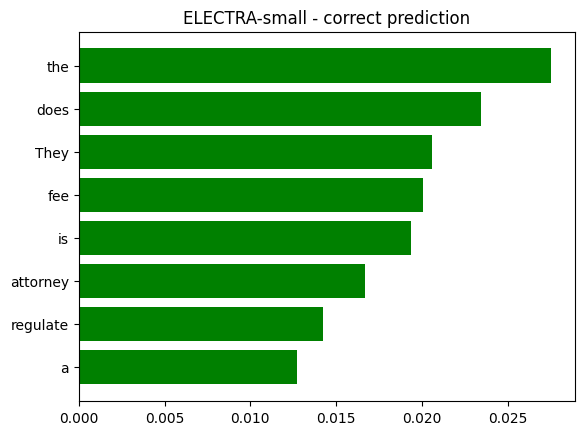


WRONG EXAMPLE | actual: AI | predicted: Human
There are 23 districts in the Indian state of West Bengal. The districts are: Alipurduar Bankura Birbhum Cooch Behar Darjeeling East Midnapore Hooghly Howrah Jalpaiguri Jhargram Kalimpong Kolkata Malda Murshidabad Nadia North 24 Parganas Paschim Bardhaman Purba Bardhaman Purulia South 24 Parganas Uttar Dinajpur Dakshin Dinajpur Darjeeling


[('Parganas', -0.020433785598662525), ('districts', -0.020355178066437177), ('Bardhaman', -0.016884385772737192), ('Dinajpur', -0.01603091394138147), ('Alipurduar', -0.014123946362799056), ('Darjeeling', -0.012738898405018028), ('Purulia', -0.011884243395459033), ('Jhargram', -0.011268296721158788)]


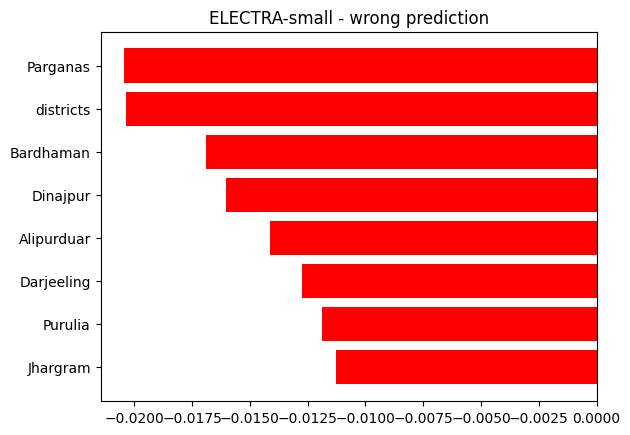

In [9]:
from lime.lime_text import LimeTextExplainer

val_probabilities = predict_proba(val.text.tolist())
val['predicted'] = val_probabilities.argmax(axis=1)
correct = val[val.label == val.predicted]
wrong = val[val.label != val.predicted]
print('Validation answers right:', len(correct), '| wrong:', len(wrong))

explainer = LimeTextExplainer(class_names=['Human', 'AI'], random_state=SEED)

for title, group in [('correct', correct), ('wrong', wrong)]:
    if len(group) == 0:
        print('No', title, 'example on the validation set.')
        continue
    row = group.iloc[0]
    print()
    print(title.upper(), 'EXAMPLE | actual:', 'AI' if row.label == 1 else 'Human',
          '| predicted:', 'AI' if row.predicted == 1 else 'Human')
    print(row.text[:400])
    explanation = explainer.explain_instance(row.text, predict_proba, labels=[int(row.predicted)],
                                             num_features=8, num_samples=300)
    print(explanation.as_list(label=int(row.predicted)))
    explanation.as_pyplot_figure(label=int(row.predicted))
    plt.title(NAME + ' - ' + title + ' prediction')
    plt.savefig(DOCS / (NAME + '-lime-' + title + '.png'), bbox_inches='tight')
    plt.show()

## 7. Final test

All choices are done (the best epoch was chosen on validation). Now we use the test set **once**.

In [10]:
test_probabilities = predict_proba(test.text.tolist())
test_predictions = test_probabilities.argmax(axis=1)

accuracy = accuracy_score(test.label, test_predictions)
precision = precision_score(test.label, test_predictions)
recall = recall_score(test.label, test_predictions)
f1 = f1_score(test.label, test_predictions)

# Speed: classify 50 answers one by one on the CPU and take the average.
predict_proba(test.text[:1].tolist())             # warm-up, not timed
start = time.perf_counter()
for text in test.text[:50]:
    predict_proba([text])
ms_per_text = (time.perf_counter() - start) / 50 * 1000

result = {'model': NAME, 'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1,
          'size_MB': size_bytes / 1_000_000, 'ms_per_text': ms_per_text}
(DOCS / (NAME + '.json')).write_text(json.dumps(result, indent=2))
pd.DataFrame([result]).round(4)

,model,accuracy,precision,recall,f1,size_MB,ms_per_text
0,ELECTRA-small,0.9533,0.9595,0.9467,0.953,55.1718,6.8943


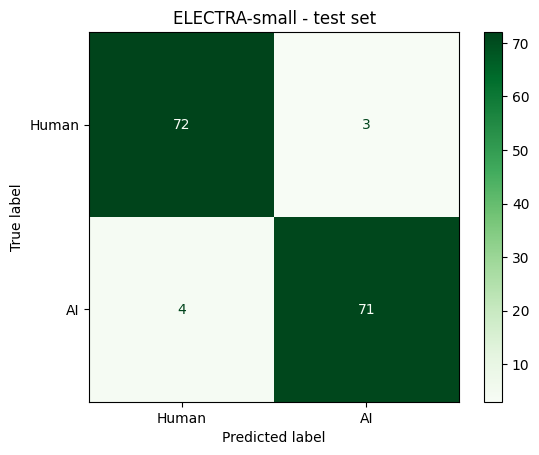

In [11]:
ConfusionMatrixDisplay.from_predictions(test.label, test_predictions, display_labels=['Human', 'AI'], cmap='Greens')
plt.title(NAME + ' - test set')
plt.savefig(DOCS / (NAME + '-matrix.png'), bbox_inches='tight')
plt.show()

## 8. Look at the mistakes

A **false positive** is a human answer called AI. A **false negative** is an AI answer called Human.

In [12]:
test['predicted'] = test_predictions
test['AI probability'] = test_probabilities[:, 1].round(3)
test['words'] = test.text.str.split().str.len()

false_positives = test[(test.label == 0) & (test.predicted == 1)]
false_negatives = test[(test.label == 1) & (test.predicted == 0)]
print('Human called AI (false positives):', len(false_positives))
print('AI called Human (false negatives):', len(false_negatives))

for title, group in [('HUMAN CALLED AI', false_positives), ('AI CALLED HUMAN', false_negatives)]:
    for i in range(min(2, len(group))):
        row = group.iloc[i]
        print()
        print(title, '| words:', row.words, '| AI probability:', row['AI probability'])
        print(row.text[:300])

Human called AI (false positives): 3
AI called Human (false negatives): 4

HUMAN CALLED AI | words: 95 | AI probability: 0.681
Dim sum refers to a style of Cantonese food prepared as small bite-sized or individual portions of food traditionally served in small steamer baskets or on small plates. Dim sum is also well known for the unique way it is served in some restaurants, wherein fully cooked and ready-to-serve dim sum di

HUMAN CALLED AI | words: 100 | AI probability: 0.645
Written by John Lennon and Paul McCartney, and recorded in October 1963, it was the first Beatles record to be made using four-track equipment. With advance orders exceeding one million copies in the United Kingdom, "I Want to Hold Your Hand" would ordinarily have gone straight to the top of the Bri

AI CALLED HUMAN | words: 21 | AI probability: 0.325
The Winter Olympics in 2006 were held in Turin, Italy. The games took place from February 10 to February 26, 2006.

AI CALLED HUMAN | words: 28 | AI probability: 0.

## Summary

- Best validation F1 0.924. **Test: accuracy 0.953, F1 0.953.** The smallest and fastest transformer: 55 MB, 7 ms per answer.
- Only 3.4 F1 points below the best model (RoBERTa), while being 5 times faster and 9 times smaller.
- Funny mistake: *"I'm sorry, but I am an AI language model…"* was called **human**. The model looks at style and length, not at meaning.
- LIME, correct example: `the`, `does`, `is` and `a` pushed the answer to AI. These are the same function words the baseline found.